# MecâniQA — OAT 3 | Tunando o Meu Modelo

**Time:** Boa Vista — Alex Oliveira Santos, Alice Gomes Aragão, Ana Clara Ribeiro da Silva, Lorran Edley Matos Ribeiro, Rodrigo dos Anjos Lamartine

## Encontro 1: modelos com hiperparâmetros padrão

## 0. Preparação: importações, dados limpos e features (OAT 1 e 2)

In [1]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score
from IPython.display import Markdown, display
import time

SEED = 42
ALVOS = ["Trocas_Oleo", "Manutencao_Motor"]
NOMES = {"Trocas_Oleo": "Trocas de Óleo", "Manutencao_Motor": "Manutenção de Motor"}
pd.options.display.float_format = "{:.2f}".format

# dados e limpeza (OAT 1)
df = pd.read_excel("mecaniqa_dataset.xlsx")
df["Data"] = pd.to_datetime(df["Data"])
df = df.set_index("Data").sort_index().asfreq("D")

for alvo in ALVOS:
    df.loc[df[alvo] < 0, alvo] = np.nan
    df[alvo] = df[alvo].interpolate(method="time")
    q1, q3 = df[alvo].quantile([0.25, 0.75])
    iqr = q3 - q1
    df[alvo] = df[alvo].clip(lower=max(0, q1 - 1.5 * iqr), upper=q3 + 1.5 * iqr)

# features (OAT 2)
df_feat = df.copy()
for alvo in ALVOS:
    for lag in [1, 7, 30]:
        df_feat[f"{alvo}_lag_{lag}"] = df_feat[alvo].shift(lag)
    df_feat[f"{alvo}_rolling_mean_7"] = df_feat[alvo].rolling(7, min_periods=7).mean().shift(1)

df_feat = df_feat.dropna()
FEATURES = [c for c in df_feat.columns if c not in ALVOS]
print(f"Dataset de features: {df_feat.shape[0]} dias, {len(FEATURES)} features")

Dataset de features: 701 dias, 8 features


## 1. Divisão temporal (treino no passado, teste no futuro)

In [2]:
n_treino = int(len(df_feat) * 0.80)
treino, teste = df_feat.iloc[:n_treino], df_feat.iloc[n_treino:]
X_treino, X_teste = treino[FEATURES], teste[FEATURES]

assert treino.index.max() < teste.index.min(), "O treino precisa terminar antes do teste!"
print(f"Treino: {treino.index.min().date()} a {treino.index.max().date()}  ({len(treino)} dias)")
print(f"Teste : {teste.index.min().date()} a {teste.index.max().date()}  ({len(teste)} dias)")

Treino: 2024-01-31 a 2025-08-12  (560 dias)
Teste : 2025-08-13 a 2025-12-31  (141 dias)


## 2. Baselines antigos (referência a ser batida) e função de erro

In [3]:
def avaliar_metricas(y_real, y_previsto):
    y_real, y_prev = np.asarray(y_real, dtype=float), np.asarray(y_previsto, dtype=float)
    mascara = y_real != 0   # MAPE não é definido quando o valor real é zero
    return {
        "RMSE": np.sqrt(mean_squared_error(y_real, y_prev)),
        "MAPE": mean_absolute_percentage_error(y_real[mascara], y_prev[mascara]) * 100,
        "MAE": mean_absolute_error(y_real, y_prev),
    }


# baselines da OAT 2
def previsao_naive(serie):
    return serie.shift(1)

def previsao_media_movel(serie, janela=7):
    return serie.rolling(janela, min_periods=janela).mean().shift(1)


# baseline de cada variável = o de menor MAE no treino
baseline_prev, baseline_nome = {}, {}
for alvo in ALVOS:
    candidatos = {"Naive": previsao_naive(df[alvo]), "Média Móvel 7d": previsao_media_movel(df[alvo])}
    mae_treino = {n: avaliar_metricas(df[alvo].loc[treino.index], p.loc[treino.index])["MAE"] for n, p in candidatos.items()}
    baseline_nome[alvo] = min(mae_treino, key=mae_treino.get)
    baseline_prev[alvo] = candidatos[baseline_nome[alvo]].loc[teste.index]
    print(f"{NOMES[alvo]}: baseline antigo = {baseline_nome[alvo]}")

Trocas de Óleo: baseline antigo = Naive
Manutenção de Motor: baseline antigo = Média Móvel 7d


## 3. Passo 1 — Instanciar modelos clássicos de regressão (hiperparâmetros default)

In [4]:
def criar_modelos():
    return {
        "Regressão Linear": LinearRegression(),
        "Árvore de Decisão": DecisionTreeRegressor(random_state=SEED),
        "Random Forest": RandomForestRegressor(random_state=SEED),
        "Gradient Boosting": GradientBoostingRegressor(random_state=SEED),
    }

modelos = {alvo: criar_modelos() for alvo in ALVOS}
print("Modelos instanciados:", list(modelos["Trocas_Oleo"].keys()))

Modelos instanciados: ['Regressão Linear', 'Árvore de Decisão', 'Random Forest', 'Gradient Boosting']


## 4. Passo 2 e 3 — Pipeline: `fit()` só no treino e `predict()` no teste

In [5]:
previsoes = {alvo: {} for alvo in ALVOS}

for alvo in ALVOS:
    for nome, modelo in modelos[alvo].items():
        modelo.fit(X_treino, treino[alvo])
        previsoes[alvo][nome] = modelo.predict(X_teste)

print("Treino e previsões concluídos para todos os modelos.")

Treino e previsões concluídos para todos os modelos.


## 5. Critério de aceite — erro inicial (RMSE e MAPE) dos modelos "crus" contra o baseline antigo

In [6]:
for alvo in ALVOS:
    b = avaliar_metricas(teste[alvo], baseline_prev[alvo])
    print(f"\n=== {NOMES[alvo]} ===")
    print(f"Baseline antigo ({baseline_nome[alvo]}) - RMSE: {b['RMSE']:.2f}, MAPE: {b['MAPE']:.2f}%")
    for nome in modelos[alvo]:
        m = avaliar_metricas(teste[alvo], previsoes[alvo][nome])
        bate = "BATE o baseline" if (m["RMSE"] < b["RMSE"] and m["MAPE"] < b["MAPE"]) else "não bate o baseline"
        print(f"{nome} - RMSE: {m['RMSE']:.2f}, MAPE: {m['MAPE']:.2f}%  ->  {bate}")


=== Trocas de Óleo ===
Baseline antigo (Naive) - RMSE: 8.92, MAPE: 26.80%
Regressão Linear - RMSE: 4.16, MAPE: 14.02%  ->  BATE o baseline
Árvore de Decisão - RMSE: 5.85, MAPE: 20.38%  ->  BATE o baseline
Random Forest - RMSE: 3.81, MAPE: 13.34%  ->  BATE o baseline
Gradient Boosting - RMSE: 4.00, MAPE: 13.70%  ->  BATE o baseline

=== Manutenção de Motor ===
Baseline antigo (Média Móvel 7d) - RMSE: 3.82, MAPE: 41.05%
Regressão Linear - RMSE: 2.42, MAPE: 26.96%  ->  BATE o baseline
Árvore de Decisão - RMSE: 3.90, MAPE: 38.37%  ->  não bate o baseline
Random Forest - RMSE: 2.48, MAPE: 28.40%  ->  BATE o baseline
Gradient Boosting - RMSE: 2.49, MAPE: 28.45%  ->  BATE o baseline


### Tabela-resumo

In [7]:
linhas = []
for alvo in ALVOS:
    b = avaliar_metricas(teste[alvo], baseline_prev[alvo])
    linhas.append({"Variável": NOMES[alvo], "Modelo": f"Baseline antigo ({baseline_nome[alvo]})", "RMSE": b["RMSE"], "MAPE (%)": b["MAPE"], "Bate o baseline?": "referência"})
    for nome in modelos[alvo]:
        m = avaliar_metricas(teste[alvo], previsoes[alvo][nome])
        bate = "SIM" if (m["RMSE"] < b["RMSE"] and m["MAPE"] < b["MAPE"]) else "não"
        linhas.append({"Variável": NOMES[alvo], "Modelo": nome, "RMSE": m["RMSE"], "MAPE (%)": m["MAPE"], "Bate o baseline?": bate})

pd.DataFrame(linhas).set_index(["Variável", "Modelo"])

RMSE  ...  Bate o baseline?
Variável            Modelo                                  ...                  
Trocas de Óleo      Baseline antigo (Naive)           8.92  ...        referência
                    Regressão Linear                  4.16  ...               SIM
                    Árvore de Decisão                 5.85  ...               SIM
                    Random Forest                     3.81  ...               SIM
                    Gradient Boosting                 4.00  ...               SIM
Manutenção de Motor Baseline antigo (Média Móvel 7d)  3.82  ...        referência
                    Regressão Linear                  2.42  ...               SIM
                    Árvore de Decisão                 3.90  ...               não
                    Random Forest                     2.48  ...               SIM
                    Gradient Boosting                 2.49  ...               SIM

[10 rows x 3 columns]

---
## Encontro 2: Grid Search com TimeSeriesSplit

### 6.1 Qual é o nosso melhor modelo? (escolha feita só no treino, sem olhar o teste)

In [8]:
tscv = TimeSeriesSplit(n_splits=5)

candidatos = {
    "Árvore de Decisão": DecisionTreeRegressor(random_state=SEED),
    "Random Forest": RandomForestRegressor(random_state=SEED),
    "Gradient Boosting": GradientBoostingRegressor(random_state=SEED),
}

cv_inicial = {alvo: {} for alvo in ALVOS}
for alvo in ALVOS:
    for nome, modelo in candidatos.items():
        scores = cross_val_score(modelo, X_treino, treino[alvo], cv=tscv,
                                 scoring="neg_root_mean_squared_error", n_jobs=-1)
        cv_inicial[alvo][nome] = -scores.mean()

tabela_cv = pd.DataFrame(cv_inicial).rename(columns=NOMES)
tabela_cv.index.name = "RMSE na validação cruzada (treino)"
for alvo in ALVOS:
    print(f"{NOMES[alvo]:<20} menor RMSE na validação: {min(cv_inicial[alvo], key=cv_inicial[alvo].get)}")
tabela_cv

Trocas de Óleo       menor RMSE na validação: Random Forest
Manutenção de Motor  menor RMSE na validação: Random Forest


,Trocas de Óleo,Manutenção de Motor
RMSE na validação cruzada (treino),,
Árvore de Decisão,9.67,3.83
Random Forest,5.86,3.00
Gradient Boosting,7.46,3.56


### 6.2 Passos 1 e 2 — Dicionário de hiperparâmetros e `GridSearchCV` com `TimeSeriesSplit`

In [9]:
# hiperparâmetros
grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 10, None],
    "min_samples_leaf": [1, 2, 4, 8],
}
n_combinacoes = int(np.prod([len(v) for v in grid.values()]))
print(f"Grid: {n_combinacoes} combinações x 5 folds = {n_combinacoes * 5} treinos por variável\n")

# GridSearchCV com TimeSeriesSplit
grid_busca, grid_tempo = {}, {}
for alvo in ALVOS:
    busca = GridSearchCV(
        estimator=RandomForestRegressor(random_state=SEED),
        param_grid=grid,
        cv=TimeSeriesSplit(n_splits=5),
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
    )
    inicio = time.perf_counter()
    busca.fit(X_treino, treino[alvo])
    duracao = time.perf_counter() - inicio
    grid_tempo[alvo] = duracao   # guarda o tempo para comparar no encontro 3
    grid_busca[alvo] = busca

    print(f"=== {NOMES[alvo]} ===")
    print("best_params_:", busca.best_params_)
    print(f"Melhor RMSE na validação cruzada: {-busca.best_score_:.3f}  | tempo: {duracao:.1f} s\n")

Grid: 48 combinações x 5 folds = 240 treinos por variável

=== Trocas de Óleo ===
best_params_: {'max_depth': None, 'min_samples_leaf': 4, 'n_estimators': 50}
Melhor RMSE na validação cruzada: 5.200  | tempo: 27.4 s

=== Manutenção de Motor ===
best_params_: {'max_depth': 10, 'min_samples_leaf': 8, 'n_estimators': 100}
Melhor RMSE na validação cruzada: 2.757  | tempo: 28.1 s



### 6.3 Critério de aceite — redução do erro em relação ao modelo da semana passada

In [10]:
ganho = {}
for alvo in ALVOS:
    prev_inicial = previsoes[alvo]["Random Forest"]
    prev_tunado = grid_busca[alvo].best_estimator_.predict(X_teste)
    m_ini = avaliar_metricas(teste[alvo], prev_inicial)
    m_tun = avaliar_metricas(teste[alvo], prev_tunado)
    cv_ini, cv_tun = cv_inicial[alvo]["Random Forest"], -grid_busca[alvo].best_score_

    tabela = pd.DataFrame(
        {
            "RMSE validação cruzada (treino)": (cv_ini, cv_tun),
            "RMSE teste": (m_ini["RMSE"], m_tun["RMSE"]),
            "MAPE teste (%)": (m_ini["MAPE"], m_tun["MAPE"]),
            "MAE teste": (m_ini["MAE"], m_tun["MAE"]),
        },
        index=["RF inicial (default)", "RF tunado (Grid Search)"],
    ).T
    tabela["Redução do erro (%)"] = (tabela.iloc[:, 0] - tabela.iloc[:, 1]) / tabela.iloc[:, 0] * 100
    ganho[alvo] = tabela

    print(f"\n=== {NOMES[alvo]} ===")
    print("best_params_:", grid_busca[alvo].best_params_)
    print(tabela.to_string())


=== Trocas de Óleo ===
best_params_: {'max_depth': None, 'min_samples_leaf': 4, 'n_estimators': 50}
                                 RF inicial (default)  RF tunado (Grid Search)  Redução do erro (%)
RMSE validação cruzada (treino)                  5.86                     5.20                11.30
RMSE teste                                       3.81                     3.82                -0.46
MAPE teste (%)                                  13.34                    13.86                -3.91
MAE teste                                        3.04                     3.13                -2.96

=== Manutenção de Motor ===
best_params_: {'max_depth': 10, 'min_samples_leaf': 8, 'n_estimators': 100}
                                 RF inicial (default)  RF tunado (Grid Search)  Redução do erro (%)
RMSE validação cruzada (treino)                  3.00                     2.76                 7.99
RMSE teste                                       2.48                     2.39                

### Conclusão

In [11]:
def frase_variacao(p):
    return f"redução de {p:.1f}%" if p >= 0 else f"aumento de {abs(p):.1f}%"


partes = ["### Resumo dos encontros\n"]
for alvo in ALVOS:
    b = avaliar_metricas(teste[alvo], baseline_prev[alvo])
    g = ganho[alvo]
    ini_rmse, tun_rmse = g.loc["RMSE teste"].iloc[0], g.loc["RMSE teste"].iloc[1]
    partes.append(
        f"**{NOMES[alvo]}**\n"
        f"- Encontro 1: o Random Forest sem ajustes já reduziu o RMSE do baseline de **{b['RMSE']:.2f}** para **{ini_rmse:.2f}**.\n"
        f"- Encontro 2: o Grid Search escolheu `{grid_busca[alvo].best_params_}`. No erro de validação houve "
        f"**{frase_variacao(g.loc['RMSE validação cruzada (treino)', 'Redução do erro (%)'])}**; no teste, o RMSE foi de {ini_rmse:.2f} para "
        f"**{tun_rmse:.2f}** ({frase_variacao(g.loc['RMSE teste', 'Redução do erro (%)'])}) e o MAPE teve "
        f"{frase_variacao(g.loc['MAPE teste (%)', 'Redução do erro (%)'])}.\n"
    )

ganhos_teste = [ganho[a].loc["RMSE teste", "Redução do erro (%)"] for a in ALVOS]
if all(abs(x) < 5 for x in ganhos_teste):
    partes.append(
        "**Leitura:** o tuning melhora o erro de validação (que é o que a busca otimiza), mas no teste o ganho adicional é pequeno, "
        "sinal de que o Random Forest com hiperparâmetros default já estava perto do teto para estes atributos. "
        "O maior salto de desempenho veio de trocar o baseline por um modelo de Machine Learning."
    )
else:
    partes.append("**Leitura:** o tuning trouxe ganho relevante também no teste, confirmando que vale a pena sintonizar o modelo.")
display(Markdown("\n".join(partes)))

### Resumo dos encontros

**Trocas de Óleo**
- Encontro 1: o Random Forest sem ajustes já reduziu o RMSE do baseline de **8.92** para **3.81**.
- Encontro 2: o Grid Search escolheu `{'max_depth': None, 'min_samples_leaf': 4, 'n_estimators': 50}`. No erro de validação houve **redução de 11.3%**; no teste, o RMSE foi de 3.81 para **3.82** (aumento de 0.5%) e o MAPE teve aumento de 3.9%.

**Manutenção de Motor**
- Encontro 1: o Random Forest sem ajustes já reduziu o RMSE do baseline de **3.82** para **2.48**.
- Encontro 2: o Grid Search escolheu `{'max_depth': 10, 'min_samples_leaf': 8, 'n_estimators': 100}`. No erro de validação houve **redução de 8.0%**; no teste, o RMSE foi de 2.48 para **2.39** (redução de 3.5%) e o MAPE teve redução de 2.8%.

**Leitura:** o tuning melhora o erro de validação (que é o que a busca otimiza), mas no teste o ganho adicional é pequeno, sinal de que o Random Forest com hiperparâmetros default já estava perto do teto para estes atributos. O maior salto de desempenho veio de trocar o baseline por um modelo de Machine Learning.

---
## Encontro 3: Random Search e eficiência

### 7.1 Passo 1 — `RandomizedSearchCV` com `n_iter` limitado

In [12]:
from sklearn.model_selection import RandomizedSearchCV

N_ITER = 10   # sorteia 10 das 48 combinações do grid

random_busca, random_tempo = {}, {}
for alvo in ALVOS:
    busca_r = RandomizedSearchCV(
        estimator=RandomForestRegressor(random_state=SEED),
        param_distributions=grid,                  # mesmo espaço de busca do Grid Search
        n_iter=N_ITER,
        cv=TimeSeriesSplit(n_splits=5),            # mesma validação temporal
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
        random_state=SEED,
    )
    inicio = time.perf_counter()
    busca_r.fit(X_treino, treino[alvo])
    random_tempo[alvo] = time.perf_counter() - inicio
    random_busca[alvo] = busca_r

    print(f"=== {NOMES[alvo]} ===")
    print("best_params_:", busca_r.best_params_)
    print(f"Melhor RMSE na validação cruzada: {-busca_r.best_score_:.3f}  | tempo: {random_tempo[alvo]:.1f} s\n")

=== Trocas de Óleo ===
best_params_: {'n_estimators': 100, 'min_samples_leaf': 4, 'max_depth': None}
Melhor RMSE na validação cruzada: 5.222  | tempo: 5.7 s

=== Manutenção de Motor ===
best_params_: {'n_estimators': 100, 'min_samples_leaf': 4, 'max_depth': None}
Melhor RMSE na validação cruzada: 2.791  | tempo: 5.7 s



### 7.2 Passos 2 e 3 — Tempo e erro: Grid Search × Random Search

In [13]:
linhas = []
for alvo in ALVOS:
    m_g = avaliar_metricas(teste[alvo], grid_busca[alvo].best_estimator_.predict(X_teste))
    m_r = avaliar_metricas(teste[alvo], random_busca[alvo].best_estimator_.predict(X_teste))
    linhas.append({
        "Variável": NOMES[alvo],
        "Treinos (Grid)": n_combinacoes * 5,
        "Treinos (Random)": N_ITER * 5,
        "Tempo Grid (s)": grid_tempo[alvo],
        "Tempo Random (s)": random_tempo[alvo],
        "Random é Nx mais rápido": grid_tempo[alvo] / random_tempo[alvo],
        "RMSE validação Grid": -grid_busca[alvo].best_score_,
        "RMSE validação Random": -random_busca[alvo].best_score_,
        "RMSE teste Grid": m_g["RMSE"],
        "RMSE teste Random": m_r["RMSE"],
        "MAPE teste Grid (%)": m_g["MAPE"],
        "MAPE teste Random (%)": m_r["MAPE"],
    })

comparativo = pd.DataFrame(linhas).set_index("Variável")
print("=== Trade-off: Grid Search x Random Search ===")
print(comparativo.T.to_string())

=== Trade-off: Grid Search x Random Search ===
Variável                 Trocas de Óleo  Manutenção de Motor
Treinos (Grid)                   240.00               240.00
Treinos (Random)                  50.00                50.00
Tempo Grid (s)                    27.41                28.12
Tempo Random (s)                   5.72                 5.72
Random é Nx mais rápido            4.80                 4.92
RMSE validação Grid                5.20                 2.76
RMSE validação Random              5.22                 2.79
RMSE teste Grid                    3.82                 2.39
RMSE teste Random                  3.84                 2.44
MAPE teste Grid (%)               13.86                27.60
MAPE teste Random (%)             13.77                28.40


### 7.3 Conclusão do trade-off (texto gerado a partir dos resultados desta execução)

In [14]:
partes = ["### Trade-off Grid Search × Random Search\n"]
for alvo in ALVOS:
    t_g, t_r = grid_tempo[alvo], random_tempo[alvo]
    r_g = comparativo.loc[NOMES[alvo], "RMSE teste Grid"]
    r_r = comparativo.loc[NOMES[alvo], "RMSE teste Random"]
    dif_pct = (r_r - r_g) / r_g * 100
    if abs(dif_pct) < 3:
        veredito = "praticamente o mesmo erro"
    elif dif_pct > 0:
        veredito = "um erro um pouco maior"
    else:
        veredito = "um erro menor"
    partes.append(
        f"- **{NOMES[alvo]}:** o Grid Search levou **{t_g:.1f} s** e o Random Search **{t_r:.1f} s** "
        f"(**{t_g / t_r:.1f}x mais rápido**, economia de {t_g - t_r:.1f} s). "
        f"O RMSE no teste foi {r_g:.2f} (Grid) contra {r_r:.2f} (Random): diferença de {r_r - r_g:+.2f} "
        f"({dif_pct:+.1f}%), ou seja, {veredito}."
    )
partes.append(
    f"\nO Random Search testou só {N_ITER} das {n_combinacoes} combinações. Para um servidor pago por tempo de uso, "
    "ele entrega o essencial do ganho por uma fração do custo; o Grid Search só compensa quando o espaço de busca é pequeno "
    "ou quando cada décimo de erro tem valor alto para o negócio."
)
display(Markdown("\n".join(partes)))

### Trade-off Grid Search × Random Search

- **Trocas de Óleo:** o Grid Search levou **27.4 s** e o Random Search **5.7 s** (**4.8x mais rápido**, economia de 21.7 s). O RMSE no teste foi 3.82 (Grid) contra 3.84 (Random): diferença de +0.02 (+0.5%), ou seja, praticamente o mesmo erro.
- **Manutenção de Motor:** o Grid Search levou **28.1 s** e o Random Search **5.7 s** (**4.9x mais rápido**, economia de 22.4 s). O RMSE no teste foi 2.39 (Grid) contra 2.44 (Random): diferença de +0.05 (+2.2%), ou seja, praticamente o mesmo erro.

O Random Search testou só 10 das 48 combinações. Para um servidor pago por tempo de uso, ele entrega o essencial do ganho por uma fração do custo; o Grid Search só compensa quando o espaço de busca é pequeno ou quando cada décimo de erro tem valor alto para o negócio.

---
## Encontro 4: Comparação final — Baseline × ML inicial × ML tunado

### 8.1 Passo 1 — Motor de métricas: MAE, RMSE e MAPE para os 3 cenários

In [15]:
def avaliar_cenarios(y_real, previsoes: dict) -> pd.DataFrame:
    """Motor de métricas: calcula MAE, RMSE e MAPE ao mesmo tempo para cada cenário."""
    tabela = pd.DataFrame({nome: avaliar_metricas(y_real, prev) for nome, prev in previsoes.items()}).T
    return tabela[["MAE", "RMSE", "MAPE"]].rename(columns={"MAPE": "MAPE (%)"})


cenarios, prev_tunado = {}, {}
for alvo in ALVOS:
    prev_tunado[alvo] = grid_busca[alvo].best_estimator_.predict(X_teste)
    cenarios[alvo] = avaliar_cenarios(teste[alvo], {
        f"Baseline antigo ({baseline_nome[alvo]})": baseline_prev[alvo],
        "ML inicial (RF default)": previsoes[alvo]["Random Forest"],
        "ML tunado (RF Grid Search)": prev_tunado[alvo],
    })

    print(f"\n=== {NOMES[alvo]} — conjunto de teste ({teste.index.min().date()} a {teste.index.max().date()}) ===")
    print(cenarios[alvo].to_string())

    base, tun = cenarios[alvo].iloc[0], cenarios[alvo].iloc[2]
    print(f"-> Tunado vs baseline: MAE {(base['MAE'] - tun['MAE']) / base['MAE'] * 100:.1f}% menor | "
          f"RMSE {(base['RMSE'] - tun['RMSE']) / base['RMSE'] * 100:.1f}% menor | "
          f"MAPE de {base['MAPE (%)']:.1f}% para {tun['MAPE (%)']:.1f}%")


=== Trocas de Óleo — conjunto de teste (2025-08-13 a 2025-12-31) ===
                            MAE  RMSE  MAPE (%)
Baseline antigo (Naive)    6.48  8.92     26.80
ML inicial (RF default)    3.04  3.81     13.34
ML tunado (RF Grid Search) 3.13  3.82     13.86
-> Tunado vs baseline: MAE 51.7% menor | RMSE 57.2% menor | MAPE de 26.8% para 13.9%

=== Manutenção de Motor — conjunto de teste (2025-08-13 a 2025-12-31) ===
                                  MAE  RMSE  MAPE (%)
Baseline antigo (Média Móvel 7d) 3.23  3.82     41.05
ML inicial (RF default)          2.05  2.48     28.40
ML tunado (RF Grid Search)       2.00  2.39     27.60
-> Tunado vs baseline: MAE 38.0% menor | RMSE 37.5% menor | MAPE de 41.1% para 27.6%


### 8.2 Passo 2 — Gráfico de linha sobreposto: Real × Baseline × Modelo tunado

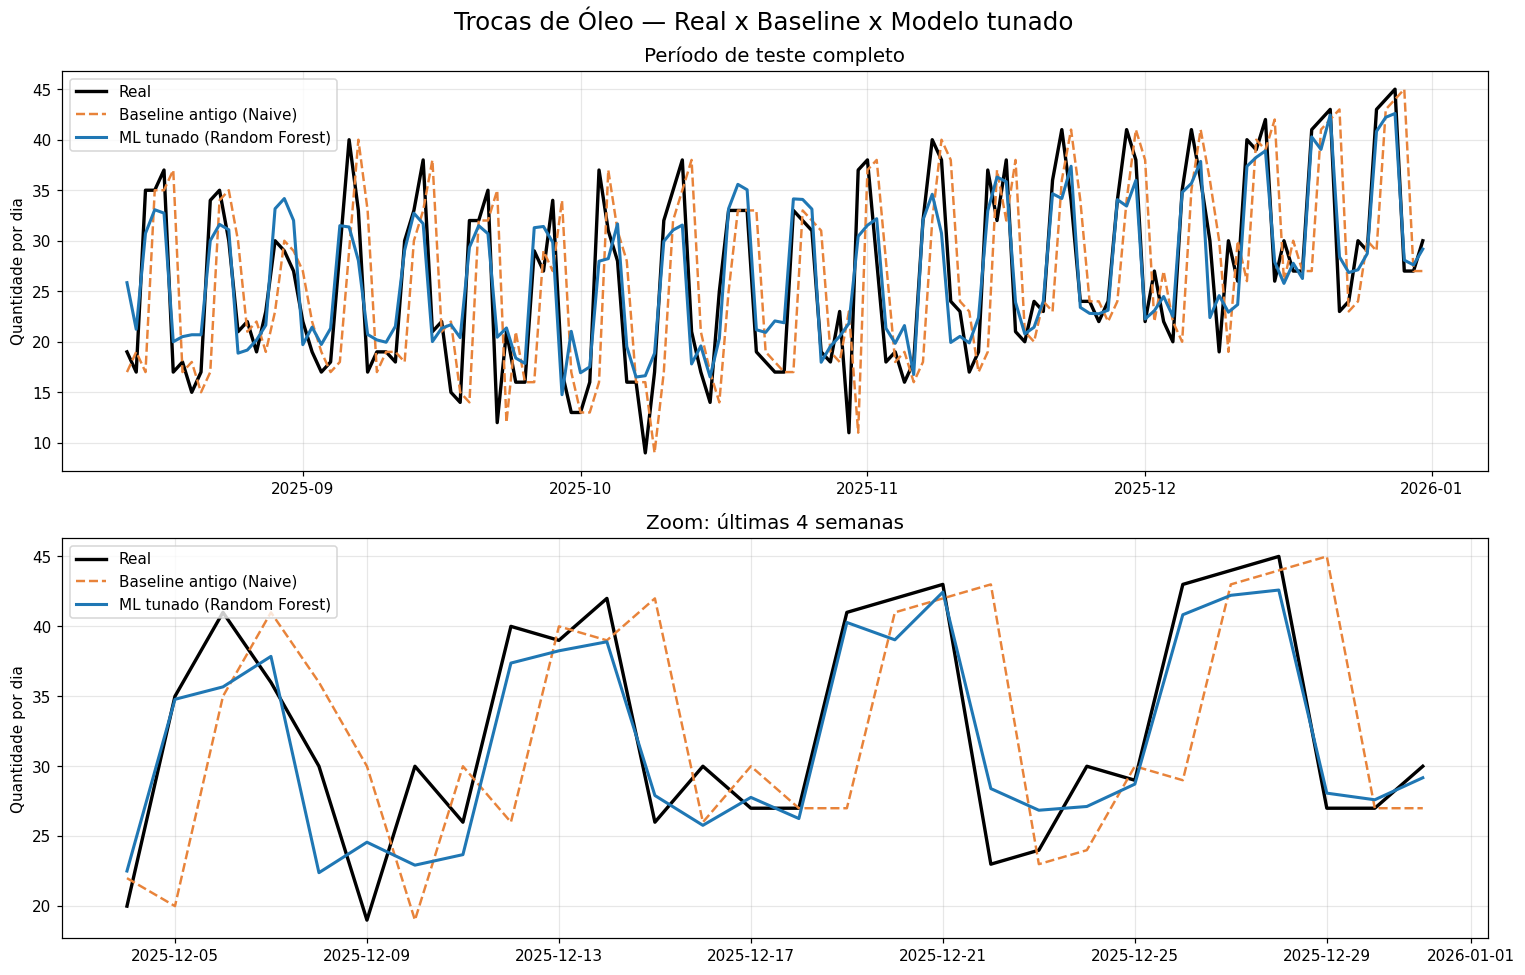

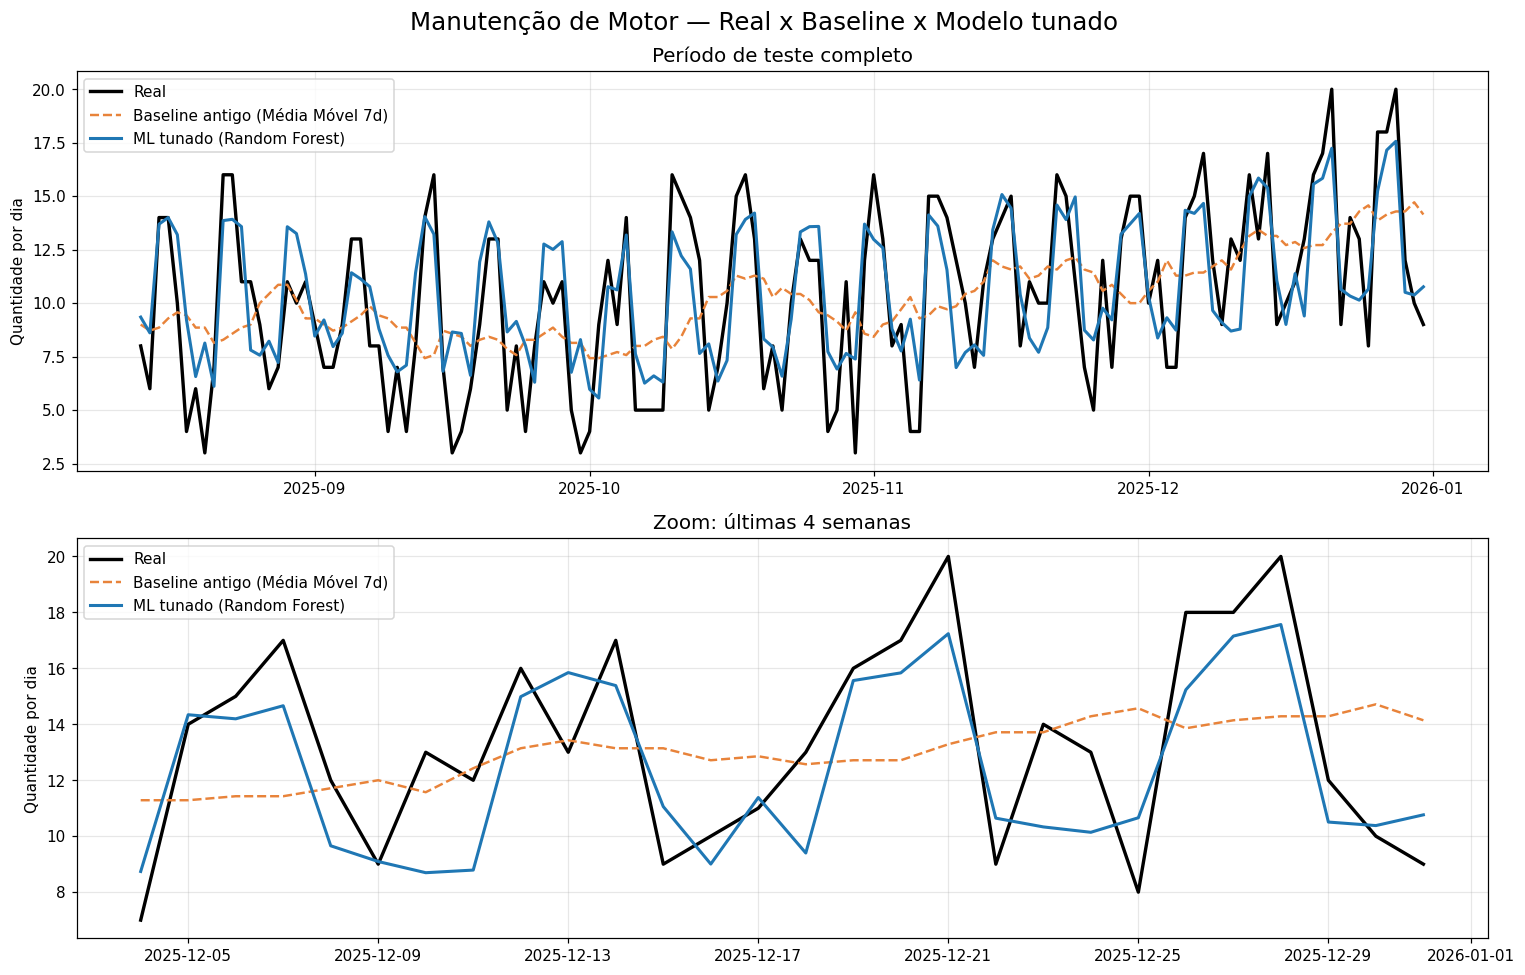

In [16]:
import matplotlib.pyplot as plt


def plotar_comparativo(alvo):
    y = teste[alvo]
    base = baseline_prev[alvo]
    tun = pd.Series(prev_tunado[alvo], index=teste.index)

    fig, axes = plt.subplots(2, 1, figsize=(14, 9))
    for ax, ultimos in zip(axes, [None, 28]):
        sl = slice(None) if ultimos is None else slice(-ultimos, None)
        ax.plot(y.index[sl], y.values[sl], color="black", lw=2.2, label="Real")
        ax.plot(base.index[sl], base.values[sl], color="#E8833A", lw=1.6, ls="--", label=f"Baseline antigo ({baseline_nome[alvo]})")
        ax.plot(tun.index[sl], tun.values[sl], color="#1F77B4", lw=2.0, label="ML tunado (Random Forest)")
        ax.set_ylabel("Quantidade por dia")
        ax.grid(alpha=0.3)
        ax.legend(loc="upper left")
    axes[0].set_title("Período de teste completo", fontsize=13)
    axes[1].set_title("Zoom: últimas 4 semanas", fontsize=13)
    fig.suptitle(f"{NOMES[alvo]} — Real x Baseline x Modelo tunado", fontsize=16)
    fig.tight_layout()
    plt.show()


plotar_comparativo("Trocas_Oleo")
plotar_comparativo("Manutencao_Motor")

### 8.3 Métricas lado a lado

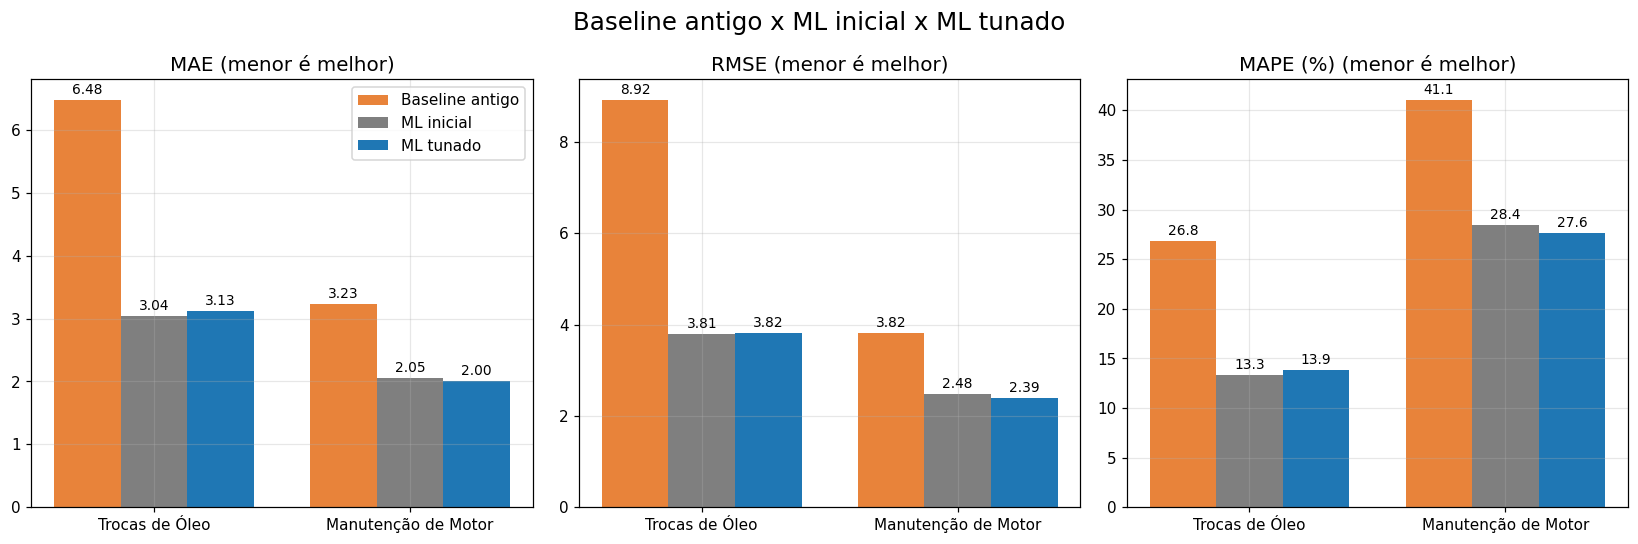

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
cores = ["#E8833A", "#7F7F7F", "#1F77B4"]
x = np.arange(len(ALVOS))
w = 0.26
for ax, metrica in zip(axes, ["MAE", "RMSE", "MAPE (%)"]):
    for i, (rotulo, cor) in enumerate(zip(["Baseline antigo", "ML inicial", "ML tunado"], cores)):
        valores = [cenarios[a][metrica].iloc[i] for a in ALVOS]
        barras = ax.bar(x + (i - 1) * w, valores, w, label=rotulo, color=cor)
        ax.bar_label(barras, fmt="%.1f" if metrica == "MAPE (%)" else "%.2f", padding=2, fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels([NOMES[a] for a in ALVOS])
    ax.set_title(metrica + " (menor é melhor)", fontsize=13)
    ax.grid(alpha=0.3)
axes[0].legend()
fig.suptitle("Baseline antigo x ML inicial x ML tunado", fontsize=16)
fig.tight_layout()
plt.show()

### 8.4 Conclusão final (texto gerado a partir dos resultados desta execução)

In [18]:
partes = ["### Resumo final — MecâniQA, OAT 3\n"]
for alvo in ALVOS:
    base, ini, tun = cenarios[alvo].iloc[0], cenarios[alvo].iloc[1], cenarios[alvo].iloc[2]
    partes.append(
        f"**{NOMES[alvo]}**\n"
        f"- O baseline antigo errava em média **{base['MAE']:.2f}** por dia (MAE); o modelo tunado erra **{tun['MAE']:.2f}**, "
        f"uma redução de **{(base['MAE'] - tun['MAE']) / base['MAE'] * 100:.0f}%**.\n"
        f"- RMSE: de {base['RMSE']:.2f} para **{tun['RMSE']:.2f}** ({(base['RMSE'] - tun['RMSE']) / base['RMSE'] * 100:.0f}% menor). "
        f"MAPE: de {base['MAPE (%)']:.1f}% para **{tun['MAPE (%)']:.1f}%**.\n"
        f"- Do modelo inicial para o tunado, o RMSE foi de {ini['RMSE']:.2f} para {tun['RMSE']:.2f}.\n"
    )
partes.append(
    "**Leitura:** o maior ganho veio de trocar o baseline por um modelo de Machine Learning alimentado pelas features temporais. "
    "A sintonia de hiperparâmetros melhorou o erro de validação, mas o ganho adicional no teste foi pequeno. "
    "O Random Search entregou praticamente o mesmo resultado do Grid Search em uma fração do tempo."
)
display(Markdown("\n".join(partes)))

### Resumo final — MecâniQA, OAT 3

**Trocas de Óleo**
- O baseline antigo errava em média **6.48** por dia (MAE); o modelo tunado erra **3.13**, uma redução de **52%**.
- RMSE: de 8.92 para **3.82** (57% menor). MAPE: de 26.8% para **13.9%**.
- Do modelo inicial para o tunado, o RMSE foi de 3.81 para 3.82.

**Manutenção de Motor**
- O baseline antigo errava em média **3.23** por dia (MAE); o modelo tunado erra **2.00**, uma redução de **38%**.
- RMSE: de 3.82 para **2.39** (37% menor). MAPE: de 41.1% para **27.6%**.
- Do modelo inicial para o tunado, o RMSE foi de 2.48 para 2.39.

**Leitura:** o maior ganho veio de trocar o baseline por um modelo de Machine Learning alimentado pelas features temporais. A sintonia de hiperparâmetros melhorou o erro de validação, mas o ganho adicional no teste foi pequeno. O Random Search entregou praticamente o mesmo resultado do Grid Search em uma fração do tempo.